# Fitting of exponential single-hit model


## Libraries

> **pandas**: Data manipulation <br>
> **numpy**: Data calculation <br>
> **matplotlib.pyplot**: Visualization <br>
> **scipy.optimize.minimize**: Numerical optimization (L-BFGS-B method) <br>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display

plt.rcParams['font.sans-serif'] = ['Noto Sans CJK JP', 'DejaVu Sans', 'sans-serif']
plt.rcParams['font.size'] = 22

## Data reading

### Dataset structure
| Column | Meaning |
|---|---|
| `Bacteria` | *E.coli* or *B.cereus* |
| `Elapsed_time_[days]` | Incubation period (3 or 7 days) |
| `Glycine_[w/v_%]`, `NaCl_[w/v_%]` | Additive concentration |
| `Inoculum_size_[CFU/well]` | Cells inoculated per well (n [CFU/well]) |
| `Number_of_growth_well` | Wells (out of 96) showing growth |

In [2]:
# read data
df = pd.read_csv("../data/data.csv", low_memory=False)
df

,Inoculum_size_[CFU/well],Glycine_[w/v_%],NaCl_[w/v_%],Wavelength_[nm],Bacteria,Elapsed_time_[days],Number_of_growth_well
0,2.79,1.6,NaN,620,B.cereus,7,0
1,2.79,1.4,NaN,620,B.cereus,7,15
2,3.11,1.6,NaN,620,B.cereus,7,0
3,3.11,1.4,NaN,620,B.cereus,7,29
4,3.12,1.6,NaN,620,B.cereus,7,4
...,...,...,...,...,...,...,...
283,130000.00,NaN,6.5,596,E.coli,3,96
284,130000.00,NaN,7.0,596,E.coli,3,79
285,173000.00,NaN,7.0,596,E.coli,3,80
286,444000.00,NaN,6.5,596,E.coli,3,96


## Model construction


\begin{equation}
  P(growth | n) = 1 - exp(-np)
\end{equation}

- Fitting algorithm: **Limited-memory Broyden–Fletcher–Goldfarb–Shanno with Bounds (L-BFGS-B)**
- This method is suitable for parameter estimation with bounded constraints (here: 0 ≤ p ≤ 1).

In [3]:
# model definition
def exponential_model(n, p):
    return 1 - np.exp(-n * p)  # P(growth | dose=n)

# loss function
def loss(p, n, y):
    pred = exponential_model(n, p[0])
    return np.sum((pred - y) ** 2)

## Result storage and helper functions

- Fit results are collected in `df_results` and displayed at the end of each figure cell
- `upsert_result` / `add_fit_result` / `add_fit_result_from_slice`: register RMSE and parameters per condition
- `se_from_lbfgsb`: standard error of *p* from the L-BFGS-B inverse Hessian

In [4]:
# ======================================
# Result DataFrame and helper functions
# ======================================

RESULT_COLUMNS = [
    "Bacterial_species",
    "Additive_type",
    "Stress_level",
    "Additive_concentration",
    "Elapsed_time_[days]",
    "model_type",
    "RMSE",
    "parameter_1",
    "parameter_2",
    "parameter_set",    # e.g. "[alpha,beta]", "[p]", "[a0,a1]"
    "p_se",            # L-BFGS-B Hessian-based standard error (SE) of p
    "p_ci95_lower",    # p_hat - 1.96 * p_se  (Gaussian approximation)
    "p_ci95_upper",    # p_hat + 1.96 * p_se  (Gaussian approximation)
]

# Empty result frame (filled by the fitting cells below)
df_results = pd.DataFrame(columns=RESULT_COLUMNS)

def upsert_result(df_results: pd.DataFrame, row_dict: dict) -> pd.DataFrame:
    """
    Update (if exists) or append (if not) a row identified by
    species + additive + stress + concentration + time + model_type.
    """
    key_cols = [
        "Bacterial_species",
        "Additive_type",
        "Stress_level",
        "Additive_concentration",
        "Elapsed_time_[days]",
        "model_type",
    ]

    if df_results.empty:
        return pd.DataFrame([row_dict], columns=df_results.columns)

    mask = np.ones(len(df_results), dtype=bool)
    for col in key_cols:
        mask &= df_results[col] == row_dict[col]

    if df_results[mask].empty:
        df_results = pd.concat([df_results, pd.DataFrame([row_dict])], ignore_index=True)
    else:
        df_results.loc[mask, row_dict.keys()] = list(row_dict.values())

    return df_results


def add_fit_result(
    df_results: pd.DataFrame,
    *,
    bacterial_species: str,
    additive_type: str,
    stress_level: str,
    additive_concentration: float,
    elapsed_time_days: int,
    model_type: str,
    y_obs: np.ndarray,
    y_pred: np.ndarray,
    params,
    parameter_names,
    p_se: float = np.nan,
) -> pd.DataFrame:
    """
    Model-agnostic helper: compute RMSE and add them to the result DataFrame.

    Parameters
    ----------
    params : sequence of floats
        Estimated parameter values (length 1 or 2).
    parameter_names : sequence of str
        Names of the parameters in the same order as `params`,
        e.g. ["alpha", "beta"], ["p"], ["a0", "a1"].
    """
    params = list(params)
    parameter_names = list(parameter_names)

    # Ensure up to two parameters are stored
    p1 = float(params[0]) if len(params) >= 1 else np.nan
    p2 = float(params[1]) if len(params) >= 2 else np.nan

    # Parameter-name set such as "[alpha,beta]" or "[p]"
    param_set_str = "[" + ",".join(parameter_names) + "]"

    rmse = float(np.sqrt(np.mean((y_pred - y_obs) ** 2)))

    # 95% symmetric CI under Gaussian approximation: p_hat +/- 1.96 * SE
    if not np.isnan(p_se):
        ci_lo = p1 - 1.96 * p_se
        ci_hi = p1 + 1.96 * p_se
    else:
        ci_lo, ci_hi = np.nan, np.nan

    row = {
        "Bacterial_species": bacterial_species,
        "Additive_type": additive_type,
        "Stress_level": stress_level,
        "Additive_concentration": additive_concentration,
        "Elapsed_time_[days]": elapsed_time_days,
        "model_type": model_type,
        "RMSE": rmse,
        "parameter_1": p1,
        "parameter_2": p2,
        "parameter_set": param_set_str,
        "p_se": float(p_se) if not np.isnan(p_se) else np.nan,
        "p_ci95_lower": ci_lo,
        "p_ci95_upper": ci_hi,
    }
    df_results = upsert_result(df_results, row)
    return df_results


def add_fit_result_from_slice(
    df_results: pd.DataFrame,
    df_slice: pd.DataFrame,
    *,
    stress_level: str,
    additive_col: str,
    model_type: str,
    y_obs: np.ndarray,
    y_pred: np.ndarray,
    params,
    parameter_names,
    p_se: float = np.nan,
) -> pd.DataFrame:
    """
    Convenience wrapper: infer metadata (species, elapsed time, additive concentration)
    from a filtered data slice (df_slice) and register RMSE and parameters.
    """

    # Infer metadata from the first row of the slice
    bacterial_species = df_slice["Bacteria"].iloc[0]
    elapsed_time_days = int(df_slice["Elapsed_time_[days]"].iloc[0])
    additive_concentration = float(df_slice[additive_col].iloc[0])

    df_results = add_fit_result(
        df_results,
        bacterial_species=bacterial_species,
        additive_type=additive_col,
        stress_level=stress_level,
        additive_concentration=additive_concentration,
        elapsed_time_days=elapsed_time_days,
        model_type=model_type,
        y_obs=y_obs,
        y_pred=y_pred,
        params=params,
        parameter_names=parameter_names,
        p_se=p_se
    )
    return df_results


def se_from_lbfgsb(res, n, y):
    """
    Approximate the standard error (SE) of p from the inverse-Hessian
    returned by L-BFGS-B.

    Model: y = exponential_model(n, p) + eps,  eps ~ N(0, sigma^2).
    For SSE = sum((pred - y)^2) minimization, the parameter covariance
    is approximated by
        Cov(p) ~= 2 * sigma^2 * H_SSE^{-1}
    where sigma^2 ~= SSE / (N - k)  (N: number of data points,
    k: number of parameters).
    res.hess_inv is a LinearOperator, so we densify it via todense().

    Returns
    -------
    p_se : float
        Standard error of p. Returns np.nan if it cannot be computed.
    """
    try:
        # res.hess_inv is a LbfgsInvHessProduct (LinearOperator)
        H_inv = np.asarray(res.hess_inv.todense())  # (k, k) matrix
        sse = float(res.fun)                        # residual sum of squares
        N = len(y)
        k = H_inv.shape[0]
        dof = max(N - k, 1)
        sigma2 = sse / dof
        # Cov(p) ~= 2 * sigma^2 * H^{-1}  (loss = sum of squared residuals;
        # the Hessian is approximately 2 * J^T J)
        cov = 2.0 * sigma2 * H_inv
        var_p = float(cov[0, 0])
        return float(np.sqrt(var_p)) if var_p > 0 else np.nan
    except Exception:
        return np.nan

# Figure 2

## _E. coli_
### Glycine
- (lower: 1.7% (w/v), higher: 1.8% (w/v))
- (A: Day3, B: Day7)
### NaCl
- (lower: 6.5% (w/v), higher: 7.0% (w/v))
- (C: Day3, D: Day7)

Estimated p(Gly, lower, Day3): 2.942e-05  SE = 2.861e-06
RMSE (Gly, lower, Day3): 0.04368
Estimated p(Gly, higher, Day3): 9.522e-06  SE = 3.907e-02
RMSE (Gly, higher, Day3): 0.02685
Estimated p(Gly, lower, Day7): 3.448e-05  SE = 3.082e-06
RMSE (Gly, lower, Day7): 0.04292
Estimated p(Gly, higher, Day7): 9.990e-06  SE = 3.104e-07
RMSE (Gly, higher, Day7): 0.01967
Estimated p(NaCl, lower, Day3): 1.086e-03  SE = 1.693e-04
RMSE (NaCl, lower, Day3): 0.10176
Estimated p(NaCl, higher, Day3): 1.109e-05  SE = 8.969e-02
RMSE (NaCl, higher, Day3): 0.06163
Estimated p(NaCl, lower, Day7): 1.415e-01  SE = 2.028e-02
RMSE (NaCl, lower, Day7): 0.08422
Estimated p(NaCl, higher, Day7): 3.663e-02  SE = 5.185e-03
RMSE (NaCl, higher, Day7): 0.07049


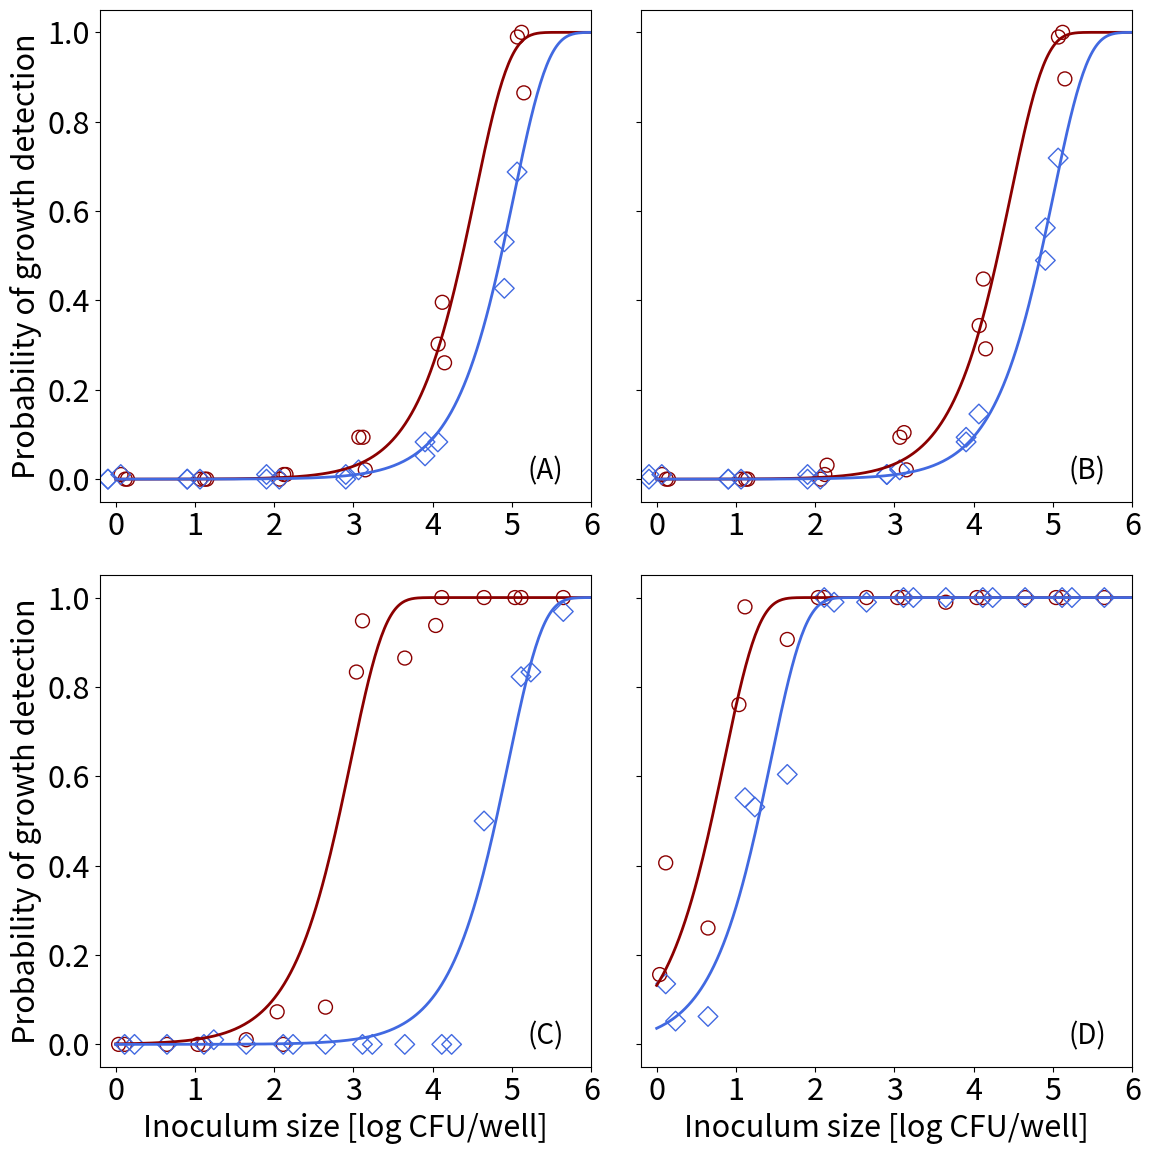

,Bacterial_species,Additive_type,Stress_level,Additive_concentration,Elapsed_time_[days],model_type,RMSE,parameter_1,parameter_2,parameter_set,p_se,p_ci95_lower,p_ci95_upper
0,E.coli,Glycine_[w/v_%],Low,1.7,3,exponential,0.043677,0.000029,NaN,[p],2.860634e-06,0.000024,0.000035
1,E.coli,Glycine_[w/v_%],High,1.8,3,exponential,0.026850,0.000010,NaN,[p],3.907313e-02,-0.076574,0.076593
2,E.coli,Glycine_[w/v_%],Low,1.7,7,exponential,0.042915,0.000034,NaN,[p],3.082230e-06,0.000028,0.000041
3,E.coli,Glycine_[w/v_%],High,1.8,7,exponential,0.019670,0.000010,NaN,[p],3.104498e-07,0.000009,0.000011
4,E.coli,NaCl_[w/v_%],Low,6.5,3,exponential,0.101756,0.001086,NaN,[p],1.693366e-04,0.000755,0.001418
5,E.coli,NaCl_[w/v_%],High,7.0,3,exponential,0.061631,0.000011,NaN,[p],8.968594e-02,-0.175773,0.175796
6,E.coli,NaCl_[w/v_%],Low,6.5,7,exponential,0.084217,0.141479,NaN,[p],2.027950e-02,0.101731,0.181227
7,E.coli,NaCl_[w/v_%],High,7.0,7,exponential,0.070489,0.036625,NaN,[p],5.185122e-03,0.026462,0.046788


In [5]:
# Exponential model by least squared method for E. coli data

df_all = df.copy()

# =====================================================================
# preprocessing - filtering
# =====================================================================
# E.coli, Day3 / Day7 (base slices)
df_Ec_day3 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 3)
].copy()
df_Ec_day7 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 7)
].copy()

# ---- Glycine conditions (lower=1.7, higher=1.8) ----
df_Ec_Gly_lower_day3 = df_Ec_day3[(df_Ec_day3["Glycine_[w/v_%]"] == 1.7)].copy()
df_Ec_Gly_higher_day3 = df_Ec_day3[(df_Ec_day3["Glycine_[w/v_%]"] == 1.8)].copy()
df_Ec_Gly_lower_day7 = df_Ec_day7[(df_Ec_day7["Glycine_[w/v_%]"] == 1.7)].copy()
df_Ec_Gly_higher_day7 = df_Ec_day7[(df_Ec_day7["Glycine_[w/v_%]"] == 1.8)].copy()

# ---- NaCl conditions (lower=6.5, higher=7.0) ----
df_Ec_NaCl_lower_day3 = df_Ec_day3[(df_Ec_day3["NaCl_[w/v_%]"] == 6.5)].copy()
df_Ec_NaCl_higher_day3 = df_Ec_day3[(df_Ec_day3["NaCl_[w/v_%]"] == 7.0)].copy()
df_Ec_NaCl_lower_day7 = df_Ec_day7[(df_Ec_day7["NaCl_[w/v_%]"] == 6.5)].copy()
df_Ec_NaCl_higher_day7 = df_Ec_day7[(df_Ec_day7["NaCl_[w/v_%]"] == 7.0)].copy()

# =====================================================================
# defining Probability of growth detection "P(n)" & removing missing values (Glycine)
# =====================================================================
# Day3, lower
df_Ec_Gly_lower_day3["Growth_probability"] = df_Ec_Gly_lower_day3["Number_of_growth_well"] / 96
df_Ec_Gly_lower_day3["Inoculum_size"] = df_Ec_Gly_lower_day3["Inoculum_size_[CFU/well]"]
df_Ec_Gly_lower_day3 = df_Ec_Gly_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
# Day3, higher
df_Ec_Gly_higher_day3["Growth_probability"] = df_Ec_Gly_higher_day3["Number_of_growth_well"] / 96
df_Ec_Gly_higher_day3["Inoculum_size"] = df_Ec_Gly_higher_day3["Inoculum_size_[CFU/well]"]
df_Ec_Gly_higher_day3 = df_Ec_Gly_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
# Day7, lower
df_Ec_Gly_lower_day7["Growth_probability"] = df_Ec_Gly_lower_day7["Number_of_growth_well"] / 96
df_Ec_Gly_lower_day7["Inoculum_size"] = df_Ec_Gly_lower_day7["Inoculum_size_[CFU/well]"]
df_Ec_Gly_lower_day7 = df_Ec_Gly_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
# Day7, higher
df_Ec_Gly_higher_day7["Growth_probability"] = df_Ec_Gly_higher_day7["Number_of_growth_well"] / 96
df_Ec_Gly_higher_day7["Inoculum_size"] = df_Ec_Gly_higher_day7["Inoculum_size_[CFU/well]"]
df_Ec_Gly_higher_day7 = df_Ec_Gly_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])

# =====================================================================
# defining Probability of growth detection "P(n)" & removing missing values (NaCl)
# =====================================================================
# Day3, lower
df_Ec_NaCl_lower_day3["Growth_probability"] = df_Ec_NaCl_lower_day3["Number_of_growth_well"] / 96
df_Ec_NaCl_lower_day3["Inoculum_size"] = df_Ec_NaCl_lower_day3["Inoculum_size_[CFU/well]"]
df_Ec_NaCl_lower_day3 = df_Ec_NaCl_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
# Day3, higher
df_Ec_NaCl_higher_day3["Growth_probability"] = df_Ec_NaCl_higher_day3["Number_of_growth_well"] / 96
df_Ec_NaCl_higher_day3["Inoculum_size"] = df_Ec_NaCl_higher_day3["Inoculum_size_[CFU/well]"]
df_Ec_NaCl_higher_day3 = df_Ec_NaCl_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
# Day7, lower
df_Ec_NaCl_lower_day7["Growth_probability"] = df_Ec_NaCl_lower_day7["Number_of_growth_well"] / 96
df_Ec_NaCl_lower_day7["Inoculum_size"] = df_Ec_NaCl_lower_day7["Inoculum_size_[CFU/well]"]
df_Ec_NaCl_lower_day7 = df_Ec_NaCl_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
# Day7, higher
df_Ec_NaCl_higher_day7["Growth_probability"] = df_Ec_NaCl_higher_day7["Number_of_growth_well"] / 96
df_Ec_NaCl_higher_day7["Inoculum_size"] = df_Ec_NaCl_higher_day7["Inoculum_size_[CFU/well]"]
df_Ec_NaCl_higher_day7 = df_Ec_NaCl_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])


# =====================================================================
# ===== fitting for Glycine, Day3 =====
# =====================================================================
# lower
n_Gly_lower_3 = df_Ec_Gly_lower_day3["Inoculum_size"].values
y_Gly_lower_3 = df_Ec_Gly_lower_day3["Growth_probability"].values
res_Gly_lower_3 = minimize(loss, x0=[0.001],
                           args=(n_Gly_lower_3, y_Gly_lower_3),
                           method="L-BFGS-B",
                           bounds=((0.0, 1.0),))
p_hat_Gly_lower_3 = res_Gly_lower_3.x[0]
p_se_Gly_lower_3 = se_from_lbfgsb(res_Gly_lower_3, n_Gly_lower_3, y_Gly_lower_3)
print(f"Estimated p(Gly, lower, Day3): {p_hat_Gly_lower_3:.3e}  SE = {p_se_Gly_lower_3:.3e}")
pred_Gly_lower_3 = exponential_model(n_Gly_lower_3, p_hat_Gly_lower_3)
rmse_Gly_lower_3 = np.sqrt(np.mean((pred_Gly_lower_3 - y_Gly_lower_3) ** 2))
print(f"RMSE (Gly, lower, Day3): {rmse_Gly_lower_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_Gly_lower_day3,
    stress_level="Low",
    additive_col="Glycine_[w/v_%]",
    model_type="exponential",
    y_obs=y_Gly_lower_3,
    y_pred=pred_Gly_lower_3,
    params=[p_hat_Gly_lower_3],
    parameter_names=["p"],
    p_se=p_se_Gly_lower_3,
)

# higher
n_Gly_higher_3 = df_Ec_Gly_higher_day3["Inoculum_size"].values
y_Gly_higher_3 = df_Ec_Gly_higher_day3["Growth_probability"].values
res_Gly_higher_3 = minimize(loss, x0=[0.001],
                            args=(n_Gly_higher_3, y_Gly_higher_3),
                            method="L-BFGS-B",
                            bounds=((0.0, 1.0),))
p_hat_Gly_higher_3 = res_Gly_higher_3.x[0]
p_se_Gly_higher_3 = se_from_lbfgsb(res_Gly_higher_3, n_Gly_higher_3, y_Gly_higher_3)
print(f"Estimated p(Gly, higher, Day3): {p_hat_Gly_higher_3:.3e}  SE = {p_se_Gly_higher_3:.3e}")
pred_Gly_higher_3 = exponential_model(n_Gly_higher_3, p_hat_Gly_higher_3)
rmse_Gly_higher_3 = np.sqrt(np.mean((pred_Gly_higher_3 - y_Gly_higher_3) ** 2))
print(f"RMSE (Gly, higher, Day3): {rmse_Gly_higher_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_Gly_higher_day3,
    stress_level="High",
    additive_col="Glycine_[w/v_%]",
    model_type="exponential",
    y_obs=y_Gly_higher_3,
    y_pred=pred_Gly_higher_3,
    params=[p_hat_Gly_higher_3],
    parameter_names=["p"],
    p_se=p_se_Gly_higher_3,
)

n_plot_Gly_lower_3 = np.logspace(0, 6, 300)
y_plot_Gly_lower_3 = exponential_model(n_plot_Gly_lower_3, p_hat_Gly_lower_3)
n_plot_Gly_higher_3 = np.logspace(0, 6, 300)
y_plot_Gly_higher_3 = exponential_model(n_plot_Gly_higher_3, p_hat_Gly_higher_3)

# =====================================================================
# ===== fitting for Glycine, Day7 =====
# =====================================================================
# lower
n_Gly_lower_7 = df_Ec_Gly_lower_day7["Inoculum_size"].values
y_Gly_lower_7 = df_Ec_Gly_lower_day7["Growth_probability"].values
res_Gly_lower_7 = minimize(loss, x0=[0.001],
                           args=(n_Gly_lower_7, y_Gly_lower_7),
                           method="L-BFGS-B",
                           bounds=((0.0, 1.0),))
p_hat_Gly_lower_7 = res_Gly_lower_7.x[0]
p_se_Gly_lower_7 = se_from_lbfgsb(res_Gly_lower_7, n_Gly_lower_7, y_Gly_lower_7)
print(f"Estimated p(Gly, lower, Day7): {p_hat_Gly_lower_7:.3e}  SE = {p_se_Gly_lower_7:.3e}")
pred_Gly_lower_7 = exponential_model(n_Gly_lower_7, p_hat_Gly_lower_7)
rmse_Gly_lower_7 = np.sqrt(np.mean((pred_Gly_lower_7 - y_Gly_lower_7) ** 2))
print(f"RMSE (Gly, lower, Day7): {rmse_Gly_lower_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_Gly_lower_day7,
    stress_level="Low",
    additive_col="Glycine_[w/v_%]",
    model_type="exponential",
    y_obs=y_Gly_lower_7,
    y_pred=pred_Gly_lower_7,
    params=[p_hat_Gly_lower_7],
    parameter_names=["p"],
    p_se=p_se_Gly_lower_7,
)

# higher
n_Gly_higher_7 = df_Ec_Gly_higher_day7["Inoculum_size"].values
y_Gly_higher_7 = df_Ec_Gly_higher_day7["Growth_probability"].values
res_Gly_higher_7 = minimize(loss, x0=[0.001],
                            args=(n_Gly_higher_7, y_Gly_higher_7),
                            method="L-BFGS-B",
                            bounds=((0.0, 1.0),))
p_hat_Gly_higher_7 = res_Gly_higher_7.x[0]
p_se_Gly_higher_7 = se_from_lbfgsb(res_Gly_higher_7, n_Gly_higher_7, y_Gly_higher_7)
print(f"Estimated p(Gly, higher, Day7): {p_hat_Gly_higher_7:.3e}  SE = {p_se_Gly_higher_7:.3e}")
pred_Gly_higher_7 = exponential_model(n_Gly_higher_7, p_hat_Gly_higher_7)
rmse_Gly_higher_7 = np.sqrt(np.mean((pred_Gly_higher_7 - y_Gly_higher_7) ** 2))
print(f"RMSE (Gly, higher, Day7): {rmse_Gly_higher_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_Gly_higher_day7,
    stress_level="High",
    additive_col="Glycine_[w/v_%]",
    model_type="exponential",
    y_obs=y_Gly_higher_7,
    y_pred=pred_Gly_higher_7,
    params=[p_hat_Gly_higher_7],
    parameter_names=["p"],
    p_se=p_se_Gly_higher_7,
)

n_plot_Gly_lower_7 = np.logspace(0, 6, 300)
y_plot_Gly_lower_7 = exponential_model(n_plot_Gly_lower_7, p_hat_Gly_lower_7)
n_plot_Gly_higher_7 = np.logspace(0, 6, 300)
y_plot_Gly_higher_7 = exponential_model(n_plot_Gly_higher_7, p_hat_Gly_higher_7)


# =====================================================================
# ===== fitting for NaCl, Day3 =====
# =====================================================================
# lower
n_NaCl_lower_3 = df_Ec_NaCl_lower_day3["Inoculum_size"].values
y_NaCl_lower_3 = df_Ec_NaCl_lower_day3["Growth_probability"].values
res_NaCl_lower_3 = minimize(loss, x0=[0.001],
                            args=(n_NaCl_lower_3, y_NaCl_lower_3),
                            method="L-BFGS-B",
                            bounds=((0.0, 1.0),))
p_hat_NaCl_lower_3 = res_NaCl_lower_3.x[0]
p_se_NaCl_lower_3 = se_from_lbfgsb(res_NaCl_lower_3, n_NaCl_lower_3, y_NaCl_lower_3)
print(f"Estimated p(NaCl, lower, Day3): {p_hat_NaCl_lower_3:.3e}  SE = {p_se_NaCl_lower_3:.3e}")
pred_NaCl_lower_3 = exponential_model(n_NaCl_lower_3, p_hat_NaCl_lower_3)
rmse_NaCl_lower_3 = np.sqrt(np.mean((pred_NaCl_lower_3 - y_NaCl_lower_3) ** 2))
print(f"RMSE (NaCl, lower, Day3): {rmse_NaCl_lower_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_NaCl_lower_day3,
    stress_level="Low",
    additive_col="NaCl_[w/v_%]",
    model_type="exponential",
    y_obs=y_NaCl_lower_3,
    y_pred=pred_NaCl_lower_3,
    params=[p_hat_NaCl_lower_3],
    parameter_names=["p"],
    p_se=p_se_NaCl_lower_3,
)

# higher
n_NaCl_higher_3 = df_Ec_NaCl_higher_day3["Inoculum_size"].values
y_NaCl_higher_3 = df_Ec_NaCl_higher_day3["Growth_probability"].values
res_NaCl_higher_3 = minimize(loss, x0=[0.001],
                             args=(n_NaCl_higher_3, y_NaCl_higher_3),
                             method="L-BFGS-B",
                             bounds=((0.0, 1.0),))
p_hat_NaCl_higher_3 = res_NaCl_higher_3.x[0]
p_se_NaCl_higher_3 = se_from_lbfgsb(res_NaCl_higher_3, n_NaCl_higher_3, y_NaCl_higher_3)
print(f"Estimated p(NaCl, higher, Day3): {p_hat_NaCl_higher_3:.3e}  SE = {p_se_NaCl_higher_3:.3e}")
pred_NaCl_higher_3 = exponential_model(n_NaCl_higher_3, p_hat_NaCl_higher_3)
rmse_NaCl_higher_3 = np.sqrt(np.mean((pred_NaCl_higher_3 - y_NaCl_higher_3) ** 2))
print(f"RMSE (NaCl, higher, Day3): {rmse_NaCl_higher_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_NaCl_higher_day3,
    stress_level="High",
    additive_col="NaCl_[w/v_%]",
    model_type="exponential",
    y_obs=y_NaCl_higher_3,
    y_pred=pred_NaCl_higher_3,
    params=[p_hat_NaCl_higher_3],
    parameter_names=["p"],
    p_se=p_se_NaCl_higher_3,
)

n_plot_NaCl_lower_3 = np.logspace(0, 6, 300)
y_plot_NaCl_lower_3 = exponential_model(n_plot_NaCl_lower_3, p_hat_NaCl_lower_3)
n_plot_NaCl_higher_3 = np.logspace(0, 6, 300)
y_plot_NaCl_higher_3 = exponential_model(n_plot_NaCl_higher_3, p_hat_NaCl_higher_3)

# =====================================================================
# ===== fitting for NaCl, Day7 =====
# =====================================================================
# lower
n_NaCl_lower_7 = df_Ec_NaCl_lower_day7["Inoculum_size"].values
y_NaCl_lower_7 = df_Ec_NaCl_lower_day7["Growth_probability"].values
res_NaCl_lower_7 = minimize(loss, x0=[0.001],
                            args=(n_NaCl_lower_7, y_NaCl_lower_7),
                            method="L-BFGS-B",
                            bounds=((0.0, 1.0),))
p_hat_NaCl_lower_7 = res_NaCl_lower_7.x[0]
p_se_NaCl_lower_7 = se_from_lbfgsb(res_NaCl_lower_7, n_NaCl_lower_7, y_NaCl_lower_7)
print(f"Estimated p(NaCl, lower, Day7): {p_hat_NaCl_lower_7:.3e}  SE = {p_se_NaCl_lower_7:.3e}")
pred_NaCl_lower_7 = exponential_model(n_NaCl_lower_7, p_hat_NaCl_lower_7)
rmse_NaCl_lower_7 = np.sqrt(np.mean((pred_NaCl_lower_7 - y_NaCl_lower_7) ** 2))
print(f"RMSE (NaCl, lower, Day7): {rmse_NaCl_lower_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_NaCl_lower_day7,
    stress_level="Low",
    additive_col="NaCl_[w/v_%]",
    model_type="exponential",
    y_obs=y_NaCl_lower_7,
    y_pred=pred_NaCl_lower_7,
    params=[p_hat_NaCl_lower_7],
    parameter_names=["p"],
    p_se=p_se_NaCl_lower_7,
)

# higher
n_NaCl_higher_7 = df_Ec_NaCl_higher_day7["Inoculum_size"].values
y_NaCl_higher_7 = df_Ec_NaCl_higher_day7["Growth_probability"].values
res_NaCl_higher_7 = minimize(loss, x0=[0.001],
                             args=(n_NaCl_higher_7, y_NaCl_higher_7),
                             method="L-BFGS-B",
                             bounds=((0.0, 1.0),))
p_hat_NaCl_higher_7 = res_NaCl_higher_7.x[0]
p_se_NaCl_higher_7 = se_from_lbfgsb(res_NaCl_higher_7, n_NaCl_higher_7, y_NaCl_higher_7)
print(f"Estimated p(NaCl, higher, Day7): {p_hat_NaCl_higher_7:.3e}  SE = {p_se_NaCl_higher_7:.3e}")
pred_NaCl_higher_7 = exponential_model(n_NaCl_higher_7, p_hat_NaCl_higher_7)
rmse_NaCl_higher_7 = np.sqrt(np.mean((pred_NaCl_higher_7 - y_NaCl_higher_7) ** 2))
print(f"RMSE (NaCl, higher, Day7): {rmse_NaCl_higher_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_NaCl_higher_day7,
    stress_level="High",
    additive_col="NaCl_[w/v_%]",
    model_type="exponential",
    y_obs=y_NaCl_higher_7,
    y_pred=pred_NaCl_higher_7,
    params=[p_hat_NaCl_higher_7],
    parameter_names=["p"],
    p_se=p_se_NaCl_higher_7,
)

n_plot_NaCl_lower_7 = np.logspace(0, 6, 300)
y_plot_NaCl_lower_7 = exponential_model(n_plot_NaCl_lower_7, p_hat_NaCl_lower_7)
n_plot_NaCl_higher_7 = np.logspace(0, 6, 300)
y_plot_NaCl_higher_7 = exponential_model(n_plot_NaCl_higher_7, p_hat_NaCl_higher_7)


#### Figure print   (2×2: A,B=Glycine / C,D=NaCl)
fig, axes = plt.subplots(2, 2, figsize=(12, 12), sharey=True)
axes = axes.flatten()   # axes[0]=A, axes[1]=B, axes[2]=C, axes[3]=D

# ---- (A) Glycine, Day3 ----
ax = axes[0]
ax.scatter(np.log10(n_Gly_lower_3), y_Gly_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
ax.plot(np.log10(n_plot_Gly_lower_3), y_plot_Gly_lower_3,
        color='darkred', lw=2)
ax.scatter(np.log10(n_Gly_higher_3), y_Gly_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
ax.plot(np.log10(n_plot_Gly_higher_3), y_plot_Gly_higher_3,
        color='royalblue', lw=2)
ax.set_ylabel("Probability of growth detection")   # left column only
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(A)', fontsize=20)
ax.set_box_aspect(1)

# ---- (B) Glycine, Day7 ----
ax = axes[1]
ax.scatter(np.log10(n_Gly_lower_7), y_Gly_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
ax.plot(np.log10(n_plot_Gly_lower_7), y_plot_Gly_lower_7,
        color='darkred', lw=2)
ax.scatter(np.log10(n_Gly_higher_7), y_Gly_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
ax.plot(np.log10(n_plot_Gly_higher_7), y_plot_Gly_higher_7,
        color='royalblue', lw=2)
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(B)', fontsize=20)
ax.set_box_aspect(1)

# ---- (C) NaCl, Day3 ----
ax = axes[2]
ax.scatter(np.log10(n_NaCl_lower_3), y_NaCl_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
ax.plot(np.log10(n_plot_NaCl_lower_3), y_plot_NaCl_lower_3,
        color='darkred', lw=2)
ax.scatter(np.log10(n_NaCl_higher_3), y_NaCl_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
ax.plot(np.log10(n_plot_NaCl_higher_3), y_plot_NaCl_higher_3,
        color='royalblue', lw=2)
ax.set_xlabel("Inoculum size [log CFU/well]")       # bottom row only
ax.set_ylabel("Probability of growth detection")   # left column only
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(C)', fontsize=20)
ax.set_box_aspect(1)

# ---- (D) NaCl, Day7 ----
ax = axes[3]
ax.scatter(np.log10(n_NaCl_lower_7), y_NaCl_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
ax.plot(np.log10(n_plot_NaCl_lower_7), y_plot_NaCl_lower_7,
        color='darkred', lw=2)
ax.scatter(np.log10(n_NaCl_higher_7), y_NaCl_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
ax.plot(np.log10(n_plot_NaCl_higher_7), y_plot_NaCl_higher_7,
        color='royalblue', lw=2)
ax.set_xlabel("Inoculum size [log CFU/well]")       # bottom row only
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(D)', fontsize=20)
ax.set_box_aspect(1)

fig.patch.set_alpha(0)
plt.tight_layout()
plt.show()
display(df_results)


# Figure 3

## _B. cereus_
### Glycine
- (lower: 1.4% (w/v), higher: 1.6% (w/v))
- (A: Day3, B: Day7)
### NaCl
- (lower: 7.0% (w/v), higher: 7.5% (w/v))
- (C: Day3, D: Day7)

Estimated p(Gly, lower, Day3): 6.151e-03  SE = 7.829e-04
RMSE (Gly, lower, Day3): 0.06553
Estimated p(Gly, higher, Day3): 5.648e-05  SE = 4.792e-06
RMSE (Gly, higher, Day3): 0.04983
Estimated p(Gly, lower, Day7): 6.098e-02  SE = 6.677e-03
RMSE (Gly, lower, Day7): 0.05703
Estimated p(Gly, higher, Day7): 9.577e-05  SE = 5.935e-06
RMSE (Gly, higher, Day7): 0.02820
Estimated p(NaCl, lower, Day3): 3.054e-03  SE = 7.358e-04
RMSE (NaCl, lower, Day3): 0.11864
Estimated p(NaCl, higher, Day3): 9.595e-05  SE = 1.492e-05
RMSE (NaCl, higher, Day3): 0.09994
Estimated p(NaCl, lower, Day7): 1.000e+00  SE = 1.344e-01
RMSE (NaCl, lower, Day7): 0.09238
Estimated p(NaCl, higher, Day7): 3.136e-01  SE = 6.140e-02
RMSE (NaCl, higher, Day7): 0.08311


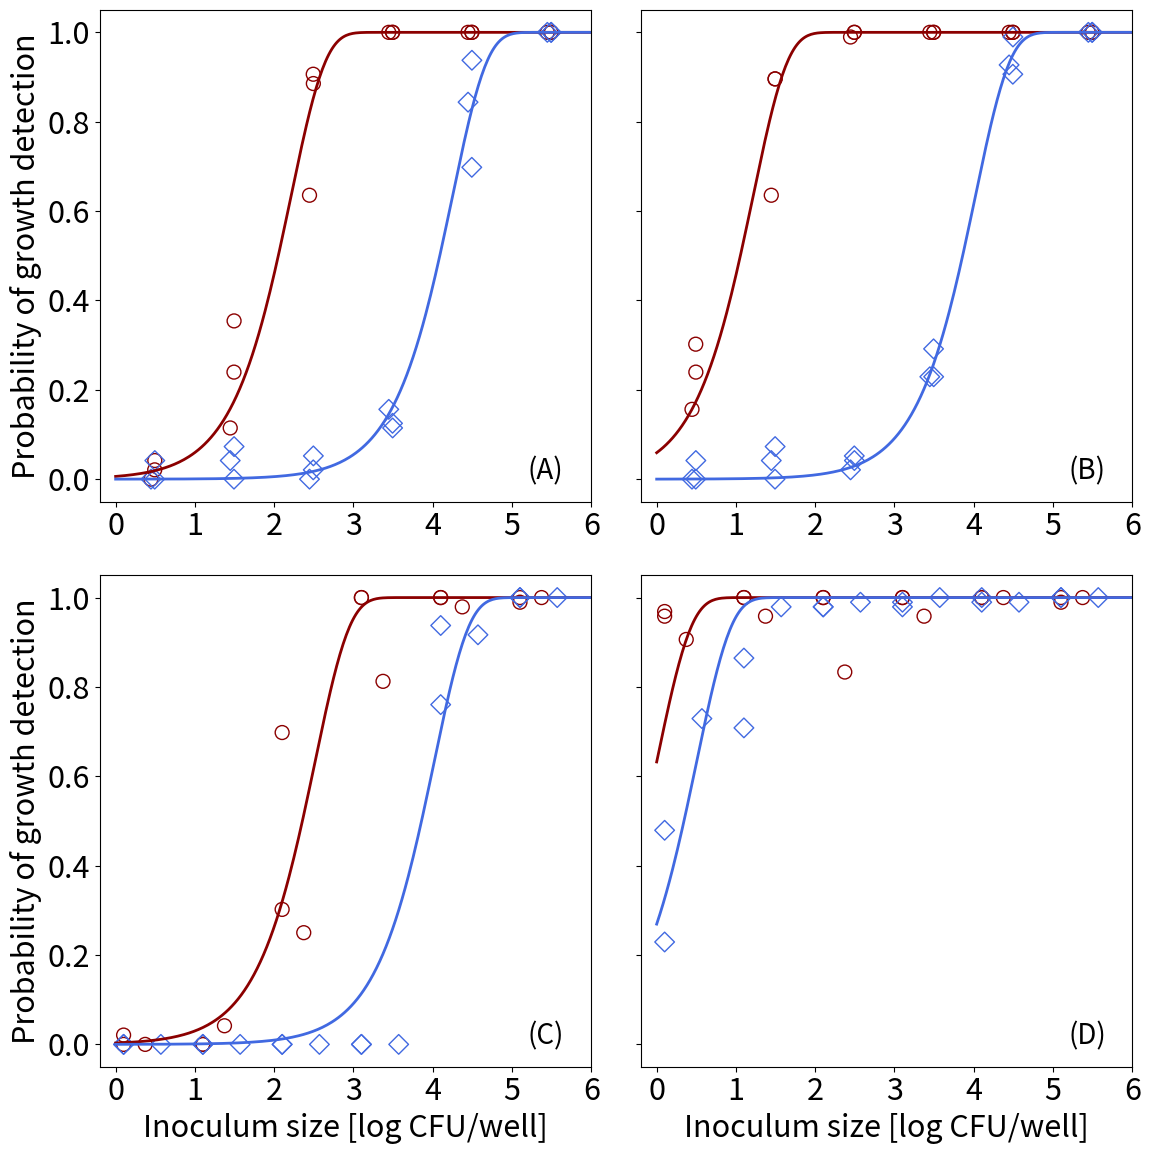

,Bacterial_species,Additive_type,Stress_level,Additive_concentration,Elapsed_time_[days],model_type,RMSE,parameter_1,parameter_2,parameter_set,p_se,p_ci95_lower,p_ci95_upper
0,E.coli,Glycine_[w/v_%],Low,1.7,3,exponential,0.043677,0.000029,NaN,[p],2.860634e-06,0.000024,0.000035
1,E.coli,Glycine_[w/v_%],High,1.8,3,exponential,0.026850,0.000010,NaN,[p],3.907313e-02,-0.076574,0.076593
2,E.coli,Glycine_[w/v_%],Low,1.7,7,exponential,0.042915,0.000034,NaN,[p],3.082230e-06,0.000028,0.000041
3,E.coli,Glycine_[w/v_%],High,1.8,7,exponential,0.019670,0.000010,NaN,[p],3.104498e-07,0.000009,0.000011
4,E.coli,NaCl_[w/v_%],Low,6.5,3,exponential,0.101756,0.001086,NaN,[p],1.693366e-04,0.000755,0.001418
5,E.coli,NaCl_[w/v_%],High,7.0,3,exponential,0.061631,0.000011,NaN,[p],8.968594e-02,-0.175773,0.175796
6,E.coli,NaCl_[w/v_%],Low,6.5,7,exponential,0.084217,0.141479,NaN,[p],2.027950e-02,0.101731,0.181227
7,E.coli,NaCl_[w/v_%],High,7.0,7,exponential,0.070489,0.036625,NaN,[p],5.185122e-03,0.026462,0.046788
8,B.cereus,Glycine_[w/v_%],Low,1.4,3,exponential,0.065526,0.006151,NaN,[p],7.828968e-04,0.004616,0.007685
9,B.cereus,Glycine_[w/v_%],High,1.6,3,exponential,0.049834,0.000056,NaN,[p],4.792271e-06,0.000047,0.000066


In [6]:
# Exponential model by least squared method for B. cereus data

df_all = df.copy()

# =====================================================================
# preprocessing - filtering
# =====================================================================
# B.cereus, Day3 / Day7 (base slices)
df_Bc_day3 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 3)
].copy()
df_Bc_day7 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 7)
].copy()

# ---- Glycine conditions (lower=1.4, higher=1.6) ----
df_Bc_Gly_lower_day3 = df_Bc_day3[(df_Bc_day3["Glycine_[w/v_%]"] == 1.4)].copy()
df_Bc_Gly_higher_day3 = df_Bc_day3[(df_Bc_day3["Glycine_[w/v_%]"] == 1.6)].copy()
df_Bc_Gly_lower_day7 = df_Bc_day7[(df_Bc_day7["Glycine_[w/v_%]"] == 1.4)].copy()
df_Bc_Gly_higher_day7 = df_Bc_day7[(df_Bc_day7["Glycine_[w/v_%]"] == 1.6)].copy()

# ---- NaCl conditions (lower=7.0, higher=7.5) ----
df_Bc_NaCl_lower_day3 = df_Bc_day3[(df_Bc_day3["NaCl_[w/v_%]"] == 7.0)].copy()
df_Bc_NaCl_higher_day3 = df_Bc_day3[(df_Bc_day3["NaCl_[w/v_%]"] == 7.5)].copy()
df_Bc_NaCl_lower_day7 = df_Bc_day7[(df_Bc_day7["NaCl_[w/v_%]"] == 7.0)].copy()
df_Bc_NaCl_higher_day7 = df_Bc_day7[(df_Bc_day7["NaCl_[w/v_%]"] == 7.5)].copy()

# =====================================================================
# defining Probability of growth detection "P(n)" & removing missing values (Glycine)
# =====================================================================
# Day3, lower
df_Bc_Gly_lower_day3["Growth_probability"] = df_Bc_Gly_lower_day3["Number_of_growth_well"] / 96
df_Bc_Gly_lower_day3["Inoculum_size"] = df_Bc_Gly_lower_day3["Inoculum_size_[CFU/well]"]
df_Bc_Gly_lower_day3 = df_Bc_Gly_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
# Day3, higher
df_Bc_Gly_higher_day3["Growth_probability"] = df_Bc_Gly_higher_day3["Number_of_growth_well"] / 96
df_Bc_Gly_higher_day3["Inoculum_size"] = df_Bc_Gly_higher_day3["Inoculum_size_[CFU/well]"]
df_Bc_Gly_higher_day3 = df_Bc_Gly_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
# Day7, lower
df_Bc_Gly_lower_day7["Growth_probability"] = df_Bc_Gly_lower_day7["Number_of_growth_well"] / 96
df_Bc_Gly_lower_day7["Inoculum_size"] = df_Bc_Gly_lower_day7["Inoculum_size_[CFU/well]"]
df_Bc_Gly_lower_day7 = df_Bc_Gly_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
# Day7, higher
df_Bc_Gly_higher_day7["Growth_probability"] = df_Bc_Gly_higher_day7["Number_of_growth_well"] / 96
df_Bc_Gly_higher_day7["Inoculum_size"] = df_Bc_Gly_higher_day7["Inoculum_size_[CFU/well]"]
df_Bc_Gly_higher_day7 = df_Bc_Gly_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])

# =====================================================================
# defining Probability of growth detection "P(n)" & removing missing values (NaCl)
# =====================================================================
# Day3, lower
df_Bc_NaCl_lower_day3["Growth_probability"] = df_Bc_NaCl_lower_day3["Number_of_growth_well"] / 96
df_Bc_NaCl_lower_day3["Inoculum_size"] = df_Bc_NaCl_lower_day3["Inoculum_size_[CFU/well]"]
df_Bc_NaCl_lower_day3 = df_Bc_NaCl_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
# Day3, higher
df_Bc_NaCl_higher_day3["Growth_probability"] = df_Bc_NaCl_higher_day3["Number_of_growth_well"] / 96
df_Bc_NaCl_higher_day3["Inoculum_size"] = df_Bc_NaCl_higher_day3["Inoculum_size_[CFU/well]"]
df_Bc_NaCl_higher_day3 = df_Bc_NaCl_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
# Day7, lower
df_Bc_NaCl_lower_day7["Growth_probability"] = df_Bc_NaCl_lower_day7["Number_of_growth_well"] / 96
df_Bc_NaCl_lower_day7["Inoculum_size"] = df_Bc_NaCl_lower_day7["Inoculum_size_[CFU/well]"]
df_Bc_NaCl_lower_day7 = df_Bc_NaCl_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
# Day7, higher
df_Bc_NaCl_higher_day7["Growth_probability"] = df_Bc_NaCl_higher_day7["Number_of_growth_well"] / 96
df_Bc_NaCl_higher_day7["Inoculum_size"] = df_Bc_NaCl_higher_day7["Inoculum_size_[CFU/well]"]
df_Bc_NaCl_higher_day7 = df_Bc_NaCl_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])


# =====================================================================
# ===== fitting for Glycine, Day3 =====
# =====================================================================
# lower
n_Gly_lower_3 = df_Bc_Gly_lower_day3["Inoculum_size"].values
y_Gly_lower_3 = df_Bc_Gly_lower_day3["Growth_probability"].values
res_Gly_lower_3 = minimize(loss, x0=[0.001],
                           args=(n_Gly_lower_3, y_Gly_lower_3),
                           method="L-BFGS-B",
                           bounds=((0.0, 1.0),))
p_hat_Gly_lower_3 = res_Gly_lower_3.x[0]
p_se_Gly_lower_3 = se_from_lbfgsb(res_Gly_lower_3, n_Gly_lower_3, y_Gly_lower_3)
print(f"Estimated p(Gly, lower, Day3): {p_hat_Gly_lower_3:.3e}  SE = {p_se_Gly_lower_3:.3e}")
pred_Gly_lower_3 = exponential_model(n_Gly_lower_3, p_hat_Gly_lower_3)
rmse_Gly_lower_3 = np.sqrt(np.mean((pred_Gly_lower_3 - y_Gly_lower_3) ** 2))
print(f"RMSE (Gly, lower, Day3): {rmse_Gly_lower_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_Gly_lower_day3,
    stress_level="Low",
    additive_col="Glycine_[w/v_%]",
    model_type="exponential",
    y_obs=y_Gly_lower_3,
    y_pred=pred_Gly_lower_3,
    params=[p_hat_Gly_lower_3],
    parameter_names=["p"],
    p_se=p_se_Gly_lower_3,
)

# higher
n_Gly_higher_3 = df_Bc_Gly_higher_day3["Inoculum_size"].values
y_Gly_higher_3 = df_Bc_Gly_higher_day3["Growth_probability"].values
res_Gly_higher_3 = minimize(loss, x0=[0.001],
                            args=(n_Gly_higher_3, y_Gly_higher_3),
                            method="L-BFGS-B",
                            bounds=((0.0, 1.0),))
p_hat_Gly_higher_3 = res_Gly_higher_3.x[0]
p_se_Gly_higher_3 = se_from_lbfgsb(res_Gly_higher_3, n_Gly_higher_3, y_Gly_higher_3)
print(f"Estimated p(Gly, higher, Day3): {p_hat_Gly_higher_3:.3e}  SE = {p_se_Gly_higher_3:.3e}")
pred_Gly_higher_3 = exponential_model(n_Gly_higher_3, p_hat_Gly_higher_3)
rmse_Gly_higher_3 = np.sqrt(np.mean((pred_Gly_higher_3 - y_Gly_higher_3) ** 2))
print(f"RMSE (Gly, higher, Day3): {rmse_Gly_higher_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_Gly_higher_day3,
    stress_level="High",
    additive_col="Glycine_[w/v_%]",
    model_type="exponential",
    y_obs=y_Gly_higher_3,
    y_pred=pred_Gly_higher_3,
    params=[p_hat_Gly_higher_3],
    parameter_names=["p"],
    p_se=p_se_Gly_higher_3,
)

n_plot_Gly_lower_3 = np.logspace(0, 6, 300)
y_plot_Gly_lower_3 = exponential_model(n_plot_Gly_lower_3, p_hat_Gly_lower_3)
n_plot_Gly_higher_3 = np.logspace(0, 6, 300)
y_plot_Gly_higher_3 = exponential_model(n_plot_Gly_higher_3, p_hat_Gly_higher_3)

# =====================================================================
# ===== fitting for Glycine, Day7 =====
# =====================================================================
# lower
n_Gly_lower_7 = df_Bc_Gly_lower_day7["Inoculum_size"].values
y_Gly_lower_7 = df_Bc_Gly_lower_day7["Growth_probability"].values
res_Gly_lower_7 = minimize(loss, x0=[0.001],
                           args=(n_Gly_lower_7, y_Gly_lower_7),
                           method="L-BFGS-B",
                           bounds=((0.0, 1.0),))
p_hat_Gly_lower_7 = res_Gly_lower_7.x[0]
p_se_Gly_lower_7 = se_from_lbfgsb(res_Gly_lower_7, n_Gly_lower_7, y_Gly_lower_7)
print(f"Estimated p(Gly, lower, Day7): {p_hat_Gly_lower_7:.3e}  SE = {p_se_Gly_lower_7:.3e}")
pred_Gly_lower_7 = exponential_model(n_Gly_lower_7, p_hat_Gly_lower_7)
rmse_Gly_lower_7 = np.sqrt(np.mean((pred_Gly_lower_7 - y_Gly_lower_7) ** 2))
print(f"RMSE (Gly, lower, Day7): {rmse_Gly_lower_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_Gly_lower_day7,
    stress_level="Low",
    additive_col="Glycine_[w/v_%]",
    model_type="exponential",
    y_obs=y_Gly_lower_7,
    y_pred=pred_Gly_lower_7,
    params=[p_hat_Gly_lower_7],
    parameter_names=["p"],
    p_se=p_se_Gly_lower_7,
)

# higher
n_Gly_higher_7 = df_Bc_Gly_higher_day7["Inoculum_size"].values
y_Gly_higher_7 = df_Bc_Gly_higher_day7["Growth_probability"].values
res_Gly_higher_7 = minimize(loss, x0=[0.001],
                            args=(n_Gly_higher_7, y_Gly_higher_7),
                            method="L-BFGS-B",
                            bounds=((0.0, 1.0),))
p_hat_Gly_higher_7 = res_Gly_higher_7.x[0]
p_se_Gly_higher_7 = se_from_lbfgsb(res_Gly_higher_7, n_Gly_higher_7, y_Gly_higher_7)
print(f"Estimated p(Gly, higher, Day7): {p_hat_Gly_higher_7:.3e}  SE = {p_se_Gly_higher_7:.3e}")
pred_Gly_higher_7 = exponential_model(n_Gly_higher_7, p_hat_Gly_higher_7)
rmse_Gly_higher_7 = np.sqrt(np.mean((pred_Gly_higher_7 - y_Gly_higher_7) ** 2))
print(f"RMSE (Gly, higher, Day7): {rmse_Gly_higher_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_Gly_higher_day7,
    stress_level="High",
    additive_col="Glycine_[w/v_%]",
    model_type="exponential",
    y_obs=y_Gly_higher_7,
    y_pred=pred_Gly_higher_7,
    params=[p_hat_Gly_higher_7],
    parameter_names=["p"],
    p_se=p_se_Gly_higher_7,
)

n_plot_Gly_lower_7 = np.logspace(0, 6, 300)
y_plot_Gly_lower_7 = exponential_model(n_plot_Gly_lower_7, p_hat_Gly_lower_7)
n_plot_Gly_higher_7 = np.logspace(0, 6, 300)
y_plot_Gly_higher_7 = exponential_model(n_plot_Gly_higher_7, p_hat_Gly_higher_7)


# =====================================================================
# ===== fitting for NaCl, Day3 =====
# =====================================================================
# lower
n_NaCl_lower_3 = df_Bc_NaCl_lower_day3["Inoculum_size"].values
y_NaCl_lower_3 = df_Bc_NaCl_lower_day3["Growth_probability"].values
res_NaCl_lower_3 = minimize(loss, x0=[0.001],
                            args=(n_NaCl_lower_3, y_NaCl_lower_3),
                            method="L-BFGS-B",
                            bounds=((0.0, 1.0),))
p_hat_NaCl_lower_3 = res_NaCl_lower_3.x[0]
p_se_NaCl_lower_3 = se_from_lbfgsb(res_NaCl_lower_3, n_NaCl_lower_3, y_NaCl_lower_3)
print(f"Estimated p(NaCl, lower, Day3): {p_hat_NaCl_lower_3:.3e}  SE = {p_se_NaCl_lower_3:.3e}")
pred_NaCl_lower_3 = exponential_model(n_NaCl_lower_3, p_hat_NaCl_lower_3)
rmse_NaCl_lower_3 = np.sqrt(np.mean((pred_NaCl_lower_3 - y_NaCl_lower_3) ** 2))
print(f"RMSE (NaCl, lower, Day3): {rmse_NaCl_lower_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_NaCl_lower_day3,
    stress_level="Low",
    additive_col="NaCl_[w/v_%]",
    model_type="exponential",
    y_obs=y_NaCl_lower_3,
    y_pred=pred_NaCl_lower_3,
    params=[p_hat_NaCl_lower_3],
    parameter_names=["p"],
    p_se=p_se_NaCl_lower_3,
)

# higher
n_NaCl_higher_3 = df_Bc_NaCl_higher_day3["Inoculum_size"].values
y_NaCl_higher_3 = df_Bc_NaCl_higher_day3["Growth_probability"].values
res_NaCl_higher_3 = minimize(loss, x0=[0.001],
                             args=(n_NaCl_higher_3, y_NaCl_higher_3),
                             method="L-BFGS-B",
                             bounds=((0.0, 1.0),))
p_hat_NaCl_higher_3 = res_NaCl_higher_3.x[0]
p_se_NaCl_higher_3 = se_from_lbfgsb(res_NaCl_higher_3, n_NaCl_higher_3, y_NaCl_higher_3)
print(f"Estimated p(NaCl, higher, Day3): {p_hat_NaCl_higher_3:.3e}  SE = {p_se_NaCl_higher_3:.3e}")
pred_NaCl_higher_3 = exponential_model(n_NaCl_higher_3, p_hat_NaCl_higher_3)
rmse_NaCl_higher_3 = np.sqrt(np.mean((pred_NaCl_higher_3 - y_NaCl_higher_3) ** 2))
print(f"RMSE (NaCl, higher, Day3): {rmse_NaCl_higher_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_NaCl_higher_day3,
    stress_level="High",
    additive_col="NaCl_[w/v_%]",
    model_type="exponential",
    y_obs=y_NaCl_higher_3,
    y_pred=pred_NaCl_higher_3,
    params=[p_hat_NaCl_higher_3],
    parameter_names=["p"],
    p_se=p_se_NaCl_higher_3,
)

n_plot_NaCl_lower_3 = np.logspace(0, 6, 300)
y_plot_NaCl_lower_3 = exponential_model(n_plot_NaCl_lower_3, p_hat_NaCl_lower_3)
n_plot_NaCl_higher_3 = np.logspace(0, 6, 300)
y_plot_NaCl_higher_3 = exponential_model(n_plot_NaCl_higher_3, p_hat_NaCl_higher_3)

# =====================================================================
# ===== fitting for NaCl, Day7 =====
# =====================================================================
# lower
n_NaCl_lower_7 = df_Bc_NaCl_lower_day7["Inoculum_size"].values
y_NaCl_lower_7 = df_Bc_NaCl_lower_day7["Growth_probability"].values
res_NaCl_lower_7 = minimize(loss, x0=[0.001],
                            args=(n_NaCl_lower_7, y_NaCl_lower_7),
                            method="L-BFGS-B",
                            bounds=((0.0, 1.0),))
p_hat_NaCl_lower_7 = res_NaCl_lower_7.x[0]
p_se_NaCl_lower_7 = se_from_lbfgsb(res_NaCl_lower_7, n_NaCl_lower_7, y_NaCl_lower_7)
print(f"Estimated p(NaCl, lower, Day7): {p_hat_NaCl_lower_7:.3e}  SE = {p_se_NaCl_lower_7:.3e}")
pred_NaCl_lower_7 = exponential_model(n_NaCl_lower_7, p_hat_NaCl_lower_7)
rmse_NaCl_lower_7 = np.sqrt(np.mean((pred_NaCl_lower_7 - y_NaCl_lower_7) ** 2))
print(f"RMSE (NaCl, lower, Day7): {rmse_NaCl_lower_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_NaCl_lower_day7,
    stress_level="Low",
    additive_col="NaCl_[w/v_%]",
    model_type="exponential",
    y_obs=y_NaCl_lower_7,
    y_pred=pred_NaCl_lower_7,
    params=[p_hat_NaCl_lower_7],
    parameter_names=["p"],
    p_se=p_se_NaCl_lower_7,
)

# higher
n_NaCl_higher_7 = df_Bc_NaCl_higher_day7["Inoculum_size"].values
y_NaCl_higher_7 = df_Bc_NaCl_higher_day7["Growth_probability"].values
res_NaCl_higher_7 = minimize(loss, x0=[0.001],
                             args=(n_NaCl_higher_7, y_NaCl_higher_7),
                             method="L-BFGS-B",
                             bounds=((0.0, 1.0),))
p_hat_NaCl_higher_7 = res_NaCl_higher_7.x[0]
p_se_NaCl_higher_7 = se_from_lbfgsb(res_NaCl_higher_7, n_NaCl_higher_7, y_NaCl_higher_7)
print(f"Estimated p(NaCl, higher, Day7): {p_hat_NaCl_higher_7:.3e}  SE = {p_se_NaCl_higher_7:.3e}")
pred_NaCl_higher_7 = exponential_model(n_NaCl_higher_7, p_hat_NaCl_higher_7)
rmse_NaCl_higher_7 = np.sqrt(np.mean((pred_NaCl_higher_7 - y_NaCl_higher_7) ** 2))
print(f"RMSE (NaCl, higher, Day7): {rmse_NaCl_higher_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_NaCl_higher_day7,
    stress_level="High",
    additive_col="NaCl_[w/v_%]",
    model_type="exponential",
    y_obs=y_NaCl_higher_7,
    y_pred=pred_NaCl_higher_7,
    params=[p_hat_NaCl_higher_7],
    parameter_names=["p"],
    p_se=p_se_NaCl_higher_7,
)

n_plot_NaCl_lower_7 = np.logspace(0, 6, 300)
y_plot_NaCl_lower_7 = exponential_model(n_plot_NaCl_lower_7, p_hat_NaCl_lower_7)
n_plot_NaCl_higher_7 = np.logspace(0, 6, 300)
y_plot_NaCl_higher_7 = exponential_model(n_plot_NaCl_higher_7, p_hat_NaCl_higher_7)


#### Figure print   (2×2: A,B=Glycine / C,D=NaCl)
fig, axes = plt.subplots(2, 2, figsize=(12, 12), sharey=True)
axes = axes.flatten()   # axes[0]=A, axes[1]=B, axes[2]=C, axes[3]=D

# ---- (A) Glycine, Day3 ----
ax = axes[0]
ax.scatter(np.log10(n_Gly_lower_3), y_Gly_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
ax.plot(np.log10(n_plot_Gly_lower_3), y_plot_Gly_lower_3,
        color='darkred', lw=2)
ax.scatter(np.log10(n_Gly_higher_3), y_Gly_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
ax.plot(np.log10(n_plot_Gly_higher_3), y_plot_Gly_higher_3,
        color='royalblue', lw=2)
ax.set_ylabel("Probability of growth detection")   # left column only
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(A)', fontsize=20)
ax.set_box_aspect(1)

# ---- (B) Glycine, Day7 ----
ax = axes[1]
ax.scatter(np.log10(n_Gly_lower_7), y_Gly_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
ax.plot(np.log10(n_plot_Gly_lower_7), y_plot_Gly_lower_7,
        color='darkred', lw=2)
ax.scatter(np.log10(n_Gly_higher_7), y_Gly_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
ax.plot(np.log10(n_plot_Gly_higher_7), y_plot_Gly_higher_7,
        color='royalblue', lw=2)
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(B)', fontsize=20)
ax.set_box_aspect(1)

# ---- (C) NaCl, Day3 ----
ax = axes[2]
ax.scatter(np.log10(n_NaCl_lower_3), y_NaCl_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
ax.plot(np.log10(n_plot_NaCl_lower_3), y_plot_NaCl_lower_3,
        color='darkred', lw=2)
ax.scatter(np.log10(n_NaCl_higher_3), y_NaCl_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
ax.plot(np.log10(n_plot_NaCl_higher_3), y_plot_NaCl_higher_3,
        color='royalblue', lw=2)
ax.set_xlabel("Inoculum size [log CFU/well]")       # bottom row only
ax.set_ylabel("Probability of growth detection")   # left column only
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(C)', fontsize=20)
ax.set_box_aspect(1)

# ---- (D) NaCl, Day7 ----
ax = axes[3]
ax.scatter(np.log10(n_NaCl_lower_7), y_NaCl_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
ax.plot(np.log10(n_plot_NaCl_lower_7), y_plot_NaCl_lower_7,
        color='darkred', lw=2)
ax.scatter(np.log10(n_NaCl_higher_7), y_NaCl_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
ax.plot(np.log10(n_plot_NaCl_higher_7), y_plot_NaCl_higher_7,
        color='royalblue', lw=2)
ax.set_xlabel("Inoculum size [log CFU/well]")       # bottom row only
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(D)', fontsize=20)
ax.set_box_aspect(1)

fig.patch.set_alpha(0)
plt.tight_layout()
plt.show()
display(df_results)

